### Uber Fare Prediction Using Regression Analysis

In [5]:
# Import the required libraries

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [6]:
# Load the dataset
df = pd.read_csv('./datasets/assignment-03.csv')

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [7]:
# Explore the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset shape: (200000, 9)

Column names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Missing values:
Unnamed: 0           0
key                  0
fare_a

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [10]:
# Remove the unneccsary identifier columns if present

df = df.drop(columns=['key','Unnamed: 0'],errors="ignore")

df = df.drop_duplicates()

df['pickup_datetime']=pd.to_datetime(
    df['pickup_datetime'],errors="coerce"
)

df=df.dropna()

df = df[(df['fare_amount']>0)&(df['passenger_count']>=1)&(df['passenger_count']<=6)]

print("Shape after basic cleaning:",df.shape)

Shape after basic cleaning: (199268, 7)


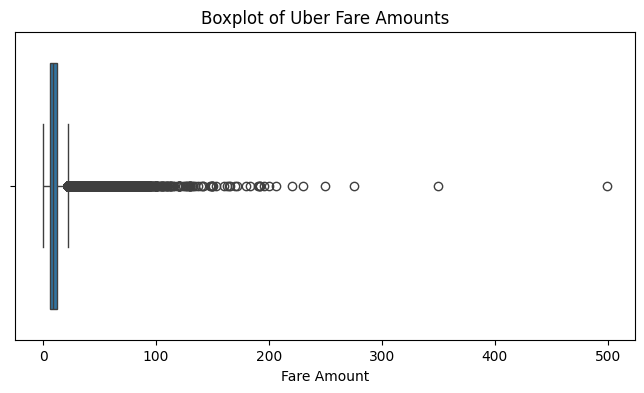

In [11]:
# Identify outliers

plt.figure(figsize=(8,4))
sns.boxplot(x=df['fare_amount'])

plt.title("Boxplot of Uber Fare Amounts")
plt.xlabel("Fare Amount")
plt.show()

In [12]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower_limit) |
    (df['fare_amount'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of fare outliers:", len(outliers))

Lower limit: -3.75
Upper limit: 22.25
Number of fare outliers: 17121


In [13]:
# Clean invalid coordinates and extreme fairs

df = df[(df['fare_amount']<=100)&
        (df['pickup_longitude'].between(-75,-72))&
        (df['dropoff_longitude'].between(-75,-72))&
        (df['pickup_latitude'].between(40,42.5))&
        (df['dropoff_latitude'].between(40,42.5))
        ].copy()
print("Shape after removing outliers and invalid coordinates:",df.shape)

Shape after removing outliers and invalid coordinates: (195023, 7)


In [14]:
# Straight line distance calculation using Haversine formula between pickup and dropoff

lat1=np.radians(df['pickup_latitude'])
lon1=np.radians(df['pickup_longitude'])
lat2=np.radians(df['dropoff_latitude'])
lon2=np.radians(df['dropoff_longitude'])

# Haversine formula
dlat=lat2 - lat1
dlon=lon2 - lon1

a = (
    np.sin(dlat/2)**2+
    np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
)

df['distance_km']= 6371 * 2 * np.arcsin(np.sqrt(a))

df = df[df['distance_km']>0].copy()

df[['fare_amount','distance_km']].head()

,fare_amount,distance_km
0,7.5,1.683323
1,7.7,2.457590
2,12.9,5.036377
3,5.3,1.661683
4,16.0,4.475450


In [15]:
# Extract time based features

df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_month'] = df['pickup_datetime'].dt.month

df[['pickup_hour','pickup_day','pickup_month']].head()

,pickup_hour,pickup_day,pickup_month
0,19,7,5
1,20,17,7
2,21,24,8
3,8,26,6
4,17,28,8


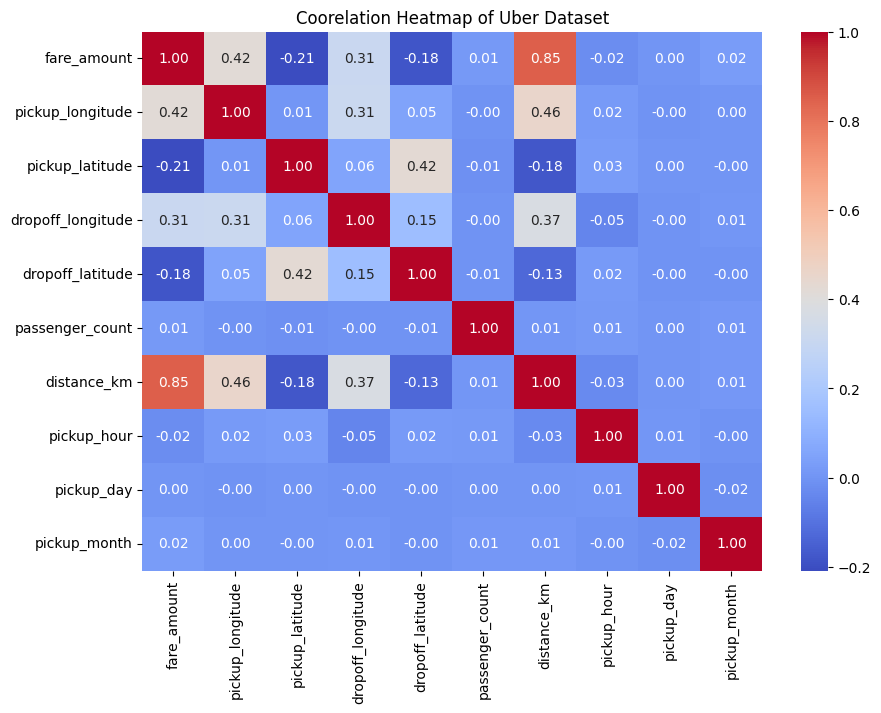

In [16]:
# Check coorelation between variables

numeric_df = df.select_dtypes(include=np.number)

coorelation = numeric_df.corr()

plt.figure(figsize=(10,7))
sns.heatmap(
    coorelation, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
)
plt.title("Coorelation Heatmap of Uber Dataset")
plt.show()

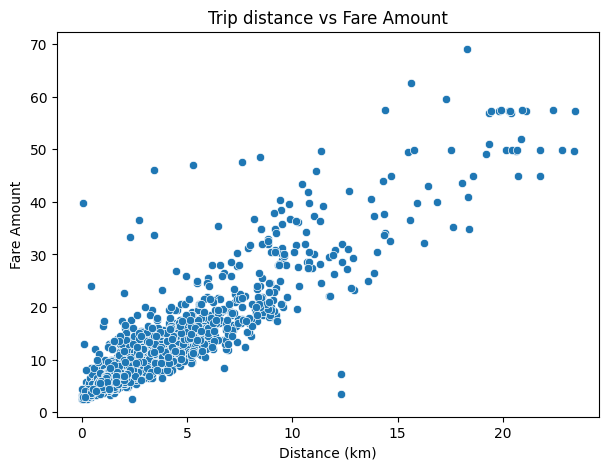

In [17]:
# Examine distance relationship with fare amount 
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df.sample(min(2000,len(df)),random_state=42),
    x="distance_km",
    y="fare_amount"
)

plt.title("Trip distance vs Fare Amount")
plt.xlabel("Distance (km)")
plt.ylabel("Fare Amount")
plt.show()

In [18]:
# Select features and target variable

features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'distance_km',
    'pickup_hour',
    'pickup_day',
    'pickup_month'
]

X = df[features]
y = df['fare_amount']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (192993, 9)
Target shape: (192993,)


In [19]:
# Train and test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 154394
Testing samples: 38599


In [20]:
# Standarize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [21]:
#Train the models
# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

# Lasso Regression
lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)

print("All three models trained successfully.")

All three models trained successfully.


In [22]:
# Evaluate and compare the models
linear_pred=linear_model.predict(X_test_scaled)
ridge_pred=ridge_model.predict(X_test_scaled)
lasso_pred=lasso_model.predict(X_test_scaled)

results=pd.DataFrame({
    'Model':['LinearRegression','RidgeRegression','LassoRegression'],
    'R2 Score':[
        r2_score(y_test, linear_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ],
    'RMSE':[
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],
    'MAE':[
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, ridge_pred),
        mean_absolute_error(y_test, lasso_pred)
    ]
})

results=results.round(3)
display(results)

,Model,R2 Score,RMSE,MAE
0,LinearRegression,0.766,4.517,2.404
1,RidgeRegression,0.766,4.517,2.404
2,LassoRegression,0.765,4.528,2.416


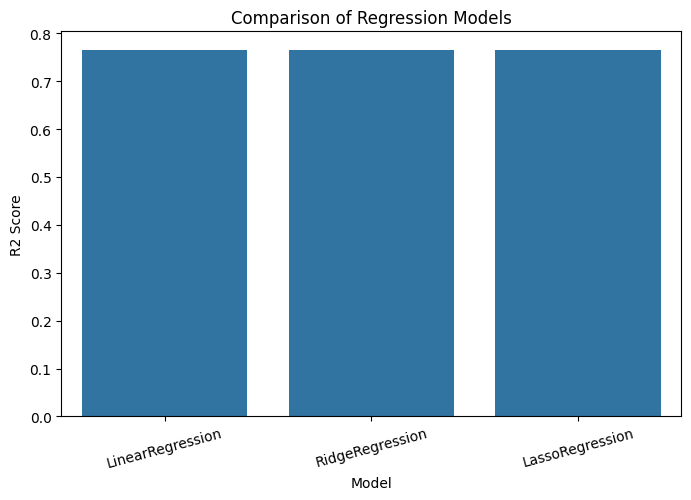

In [23]:
# Visualize the model comparison
plt.figure(figsize=(8,5))

sns.barplot(data=results,x="Model",y="R2 Score")

plt.title("Comparison of Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.show()

In [24]:
#  Predict a fare using the trained model

comparison = pd.DataFrame({
    'Actual Fare': y_test.iloc[:10].values,
    'Predicted Fare': linear_pred[:10]
})

comparison['Predicted Fare'] = comparison['Predicted Fare'].round(2)

display(comparison.round(2))

,Actual Fare,Predicted Fare
0,14.1,13.03
1,7.5,10.07
2,5.3,5.98
3,8.0,8.21
4,7.3,27.53
5,14.5,13.35
6,6.5,6.07
7,10.1,10.22
8,11.3,13.27
9,18.5,17.54
